# Three-stage framework vs. OAENet — paper-mode replication (Python)

This notebook replicates the synthetic experiments of the three-stage paper (Section 6.1, Figures 3 and 4)
with `causal_fs.py` in **paper mode**, which follows `FS_CI_Final.R`:

| Step | Paper mode |
|---|---|
| Data | $X \sim N(0,\Sigma)$, $\Sigma_{jk}=\rho$, $p=20$, X standardised after generation; $A = 1\{U < \text{expit}(X\alpha)\}$; $Y = X\beta + N(0,1) + 0.5A$ |
| Coefficients | multiplied by `COEF_MULT` (2 in `FS_CI_Final.R`; 1 = values printed in Section 6.1) |
| Stage 2 | relaxed `cv.glmnet` ($\alpha=0.5$), `lambda.1se`, relaxed $\gamma$ |
| Stage 3 | `msaenet::aenet` ($\alpha$ grid 0.05–0.95), `lambda.1se` |
| Selection | $|\Theta| \ge 0.1$ |
| ONet | the OAENet benchmark of `FS_CI_Final.R` (wAMD tuning) |
| ATT | 1:1 nearest-neighbour PS matching, caliper 0.25, common support; coefficient of $A$ in `lm(Y ~ A + X)` |
| Metric | percentage selection bias $|\widehat{ATT} - \widehat{ATT}_{target}| / 0.5 \times 100$, where the target model matches on $X_1$–$X_4$ |

Variables: $X_1$–$X_2$ confounders, $X_3$–$X_4$ pure outcome predictors, $X_5$–$X_6$ pure treatment predictors, $X_7$–$X_{20}$ noise.

Put `causal_fs.py` in the same folder as this notebook.

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from causal_fs import three_stage, oaenet, att_matching

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

## 1. Settings

In [2]:
COEF_MULT = 2.0                  # 2 = FS_CI_Final.R ; 1 = coefficients as printed in Section 6.1
N         = 200
P         = 20
REPS      = 30                   # seeds 1..REPS
RHO_LIST  = [0, 0.25, 0.5, 0.75]
SCENARIOS = [1, 2, 3, 4]
OUT_FILE  = Path(f"simulation_results_paper_py_mult{COEF_MULT:g}.csv")
RESUME    = True                 # skip data sets already in OUT_FILE

# optional comparisons
R_RESULTS = Path("simulation_results_paper_R.csv")   # output of simulate_demo.R (set to None to skip)
R_EXPORT  = None                                     # e.g. Path("r_export"): data sets exported by simulate_demo.R

## 2. Data-generating process

In [3]:
SCEN = {   # (beta: outcome model, alpha: treatment model), as printed in Section 6.1
    1: ([.6, .6, .6, .6], [1, 1, 0, 0, 1, 1]),
    2: ([.6, .6, .6, .6], [.4, .4, 0, 0, 1, 1]),
    3: ([.2, .2, .6, .6], [1, 1, 0, 0, 1, 1]),
    4: ([.6, .6, .6, .6], [1, 1, 0, 0, 1.8, 1.8]),
}

def simulate(n, rho, scenario, seed, coef_mult=COEF_MULT, p=P):
    rng = np.random.default_rng(seed)
    beta = np.zeros(p); alpha = np.zeros(p)
    beta[:4] = SCEN[scenario][0]; alpha[:6] = SCEN[scenario][1]
    beta, alpha = coef_mult * beta, coef_mult * alpha
    S = np.full((p, p), rho); np.fill_diagonal(S, 1.0)
    X = rng.multivariate_normal(np.zeros(p), S, size=n)
    A = (rng.uniform(size=n) < expit(X @ alpha)).astype(int)
    Y = X @ beta + rng.normal(size=n) + 0.5 * A
    X = (X - X.mean(0)) / X.std(0, ddof=1)
    return X, Y, A

X, Y, A = simulate(N, 0.25, 1, 1)
print(X.shape, "treated share:", A.mean().round(3))

(200, 20) treated share: 0.5


## 3. Methods (paper mode)

In [4]:
METHODS = {
    "Enh-ELRT":  lambda X, Y, A, s: three_stage(X, Y, A, prior="LR",  smoother="tanh",    seed=s, mode="paper")["selected"],
    "Enh-ESVMS": lambda X, Y, A, s: three_stage(X, Y, A, prior="SVM", smoother="sigmoid", seed=s, mode="paper")["selected"],
    "ONet":      lambda X, Y, A, s: oaenet(X, Y, A, mode="paper")["selected"],
}

def one_dataset(X, Y, A, s, **keys):
    tgt = att_matching(X[:, :4], Y, A, mode="paper")                 # target model: X1-X4
    rows = []
    for name, f in METHODS.items():
        t0 = time.time(); sel = np.asarray(f(X, Y, A, s)); el = time.time() - t0
        att = att_matching(X[:, sel], Y, A, mode="paper")
        r = dict(keys, method=name, n_selected=len(sel), att=att, att_target=tgt,
                 pct_bias=100 * abs(att - tgt) / 0.5, seconds=el)
        for j in range(X.shape[1]):
            r[f"X{j + 1}"] = int(j in set(sel.tolist()))
        rows.append(r)
    return rows

# quick check on one data set
pd.DataFrame(one_dataset(X, Y, A, 1, scenario=1, rho=0.25, seed=1))[["method", "n_selected", "att", "att_target", "pct_bias", "seconds"]]

,method,n_selected,att,att_target,pct_bias,seconds
0,Enh-ELRT,4,0.560558,0.560558,0.0,12.860660
1,Enh-ESVMS,4,0.560558,0.560558,0.0,10.879721
2,ONet,4,0.560558,0.560558,0.0,1.227950


## 4. Run the grid
Results are written after every data set, so an interrupted run can be resumed (`RESUME = True`).

In [5]:
rows = pd.read_csv(OUT_FILE).to_dict("records") if (RESUME and OUT_FILE.exists()) else []
done = {(r["scenario"], r["rho"], r["seed"]) for r in rows}
t_start = time.time()
for sc in SCENARIOS:
    for rho in RHO_LIST:
        for seed in range(1, REPS + 1):
            if (sc, rho, seed) in done:
                continue
            X, Y, A = simulate(N, rho, sc, seed)
            rows += one_dataset(X, Y, A, seed, scenario=sc, rho=rho, seed=seed)
            pd.DataFrame(rows).to_csv(OUT_FILE, index=False)
        print(f"scenario {sc}  rho {rho}  done  ({time.time() - t_start:.0f}s)", flush=True)
res = pd.DataFrame(rows)
print(res.shape)

scenario 1  rho 0  done  (464s)
scenario 1  rho 0.25  done  (729s)
scenario 1  rho 0.5  done  (949s)
scenario 1  rho 0.75  done  (1451s)
scenario 2  rho 0  done  (2054s)
scenario 2  rho 0.25  done  (2714s)
scenario 2  rho 0.5  done  (3375s)
scenario 2  rho 0.75  done  (4011s)
scenario 3  rho 0  done  (4631s)
scenario 3  rho 0.25  done  (5369s)
scenario 3  rho 0.5  done  (6224s)
scenario 3  rho 0.75  done  (6829s)
scenario 4  rho 0  done  (7015s)
scenario 4  rho 0.25  done  (7312s)
scenario 4  rho 0.5  done  (8041s)
scenario 4  rho 0.75  done  (8904s)
(1440, 29)


## 5. Summary tables

In [6]:
def add_groups(d):
    d = d.copy()
    d["XC"] = d[["X1", "X2"]].mean(axis=1); d["XP"] = d[["X3", "X4"]].mean(axis=1)
    d["XT"] = d[["X5", "X6"]].mean(axis=1); d["XS"] = d[[f"X{j}" for j in range(7, P + 1)]].mean(axis=1)
    return d

res = add_groups(res)
by_rho = res.groupby(["scenario", "rho", "method"]).agg(
    XC=("XC", "mean"), XP=("XP", "mean"), XT=("XT", "mean"), XS=("XS", "mean"),
    pct_bias=("pct_bias", "mean"), n_failed=("att", lambda s: int(s.isna().sum()))).round(3)
by_rho

XC     XP     XT     XS  pct_bias  n_failed
scenario rho  method                                                   
1        0.00 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       1.000  0.900  0.033  0.000     9.144         0
         0.25 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       1.000  0.917  0.000  0.012     6.087         0
         0.50 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       1.000  0.983  0.017  0.019    10.904         0
         0.75 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       1.000  0.983  0.033  0.024    13.688         0
2        0.00 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       1.000  0.850  0.017  0.000     5.018         0
         0.25 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       1.000  0.983  0.000  0.007     0.724         0
         0.50 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       1.000  1.000  0.017  0.010     3.271         0
         0.75 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       1.000  0.983  0.050  0.038    12.974         0
3        0.00 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       0.967  0.950  0.033  0.000     9.480         0
         0.25 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       1.000  0.950  0.000  0.012     4.917         0
         0.50 Enh-ELRT   0.900  1.000  0.000  0.005     8.701         0
              Enh-ESVMS  0.967  1.000  0.000  0.000     4.289         0
              ONet       0.967  0.983  0.017  0.019    16.524         0
         0.75 Enh-ELRT   0.783  1.000  0.000  0.005    15.769         0
              Enh-ESVMS  0.767  1.000  0.000  0.002    16.031         0
              ONet       0.833  0.967  0.033  0.029    22.606         0
4        0.00 Enh-ELRT   1.000  1.000  0.017  0.000     2.143         0
              Enh-ESVMS  1.000  1.000  0.017  0.000     2.143         0
              ONet       1.000  0.850  0.067  0.000     7.121         0
         0.25 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       1.000  0.933  0.000  0.000     2.760         0
         0.50 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       1.000  0.983  0.017  0.010     4.408         0
         0.75 Enh-ELRT   1.000  1.000  0.000  0.000     0.000         0
              Enh-ESVMS  1.000  1.000  0.000  0.000     0.000         0
              ONet       1.000  1.000  0.033  0.029    15.855         0

In [7]:
# Figure 3 layout: percentage selection bias pooled over rho, 90% CI of the mean
fig3 = res.groupby(["scenario", "method"]).pct_bias.apply(
    lambda s: f"{s.mean():.1f} [{max(s.mean() - 1.645 * s.std(ddof=1) / np.sqrt(s.count()), 0):.1f}, "
              f"{s.mean() + 1.645 * s.std(ddof=1) / np.sqrt(s.count()):.1f}]").unstack()
fig3

method,Enh-ELRT,Enh-ESVMS,ONet
scenario,,,
1,"0.0 [0.0, 0.0]","0.0 [0.0, 0.0]","10.0 [6.6, 13.3]"
2,"0.0 [0.0, 0.0]","0.0 [0.0, 0.0]","5.5 [3.5, 7.5]"
3,"6.1 [3.4, 8.9]","5.1 [2.6, 7.6]","13.4 [9.6, 17.1]"
4,"0.5 [0.0, 1.4]","0.5 [0.0, 1.4]","7.5 [4.8, 10.2]"


## 6. Figures

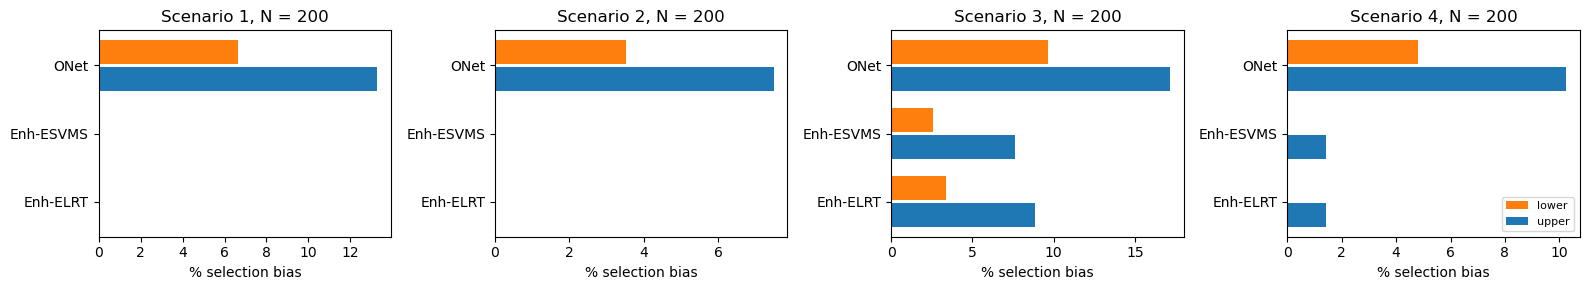

In [8]:
# Figure 3 style: 90% CI of the percentage selection bias, pooled over rho
fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(4 * len(SCENARIOS), 3), sharex=False)
for ax, sc in zip(np.atleast_1d(axes), SCENARIOS):
    d = res[res.scenario == sc]
    stats = d.groupby("method").pct_bias.agg(["mean", "std", "count"])
    se = stats["std"] / np.sqrt(stats["count"])
    lo, hi = (stats["mean"] - 1.645 * se).clip(lower=0), stats["mean"] + 1.645 * se
    y = np.arange(len(stats))
    ax.barh(y + 0.2, lo, height=0.35, label="lower", color="tab:orange")
    ax.barh(y - 0.2, hi, height=0.35, label="upper", color="tab:blue")
    ax.set_yticks(y); ax.set_yticklabels(stats.index); ax.set_title(f"Scenario {sc}, N = {N}")
    ax.set_xlabel("% selection bias")
np.atleast_1d(axes)[-1].legend(fontsize=8)
plt.tight_layout(); plt.show()

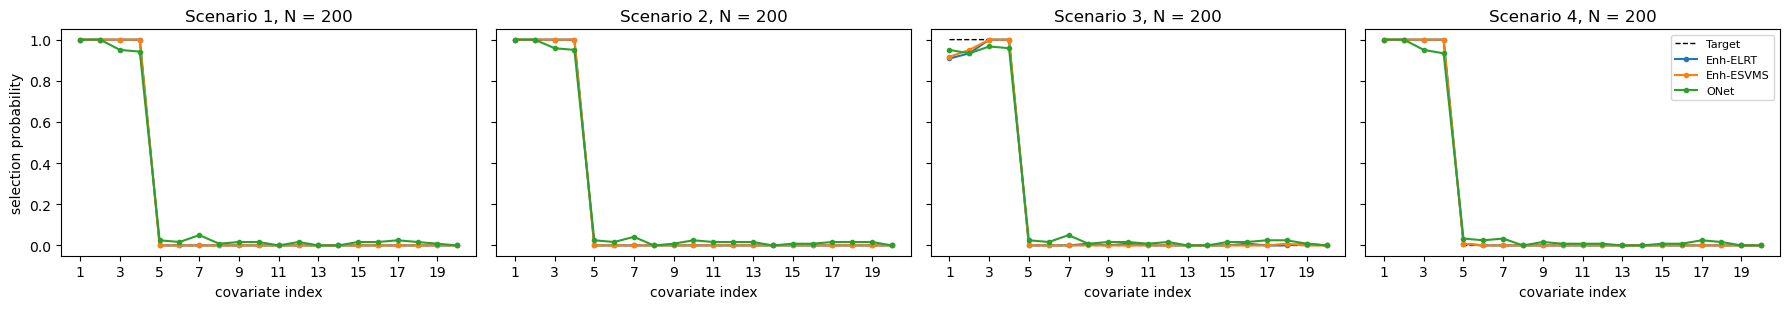

In [9]:
# Figure 4 style: probability of each variable being selected, pooled over rho
vars_ = [f"X{j}" for j in range(1, P + 1)]
fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(4.5 * len(SCENARIOS), 3.2), sharey=True)
for ax, sc in zip(np.atleast_1d(axes), SCENARIOS):
    d = res[res.scenario == sc].groupby("method")[vars_].mean()
    ax.plot(range(1, P + 1), [1] * 4 + [0] * (P - 4), "k--", lw=1, label="Target")
    for m, row in d.iterrows():
        ax.plot(range(1, P + 1), row.values, marker="o", ms=3, label=m)
    ax.set_title(f"Scenario {sc}, N = {N}"); ax.set_xlabel("covariate index"); ax.set_xticks(range(1, P + 1, 2))
np.atleast_1d(axes)[0].set_ylabel("selection probability"); np.atleast_1d(axes)[-1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Comparison with the R results (`simulate_demo.R`)
R and Python use different random numbers, so they are compared in distribution, cell by cell.

In [10]:
from scipy import stats
if R_RESULTS is not None and Path(R_RESULTS).exists():
    rr = add_groups(pd.read_csv(R_RESULTS))
    cols = ["XC", "XP", "XT", "pct_bias"]
    a = rr.groupby(["scenario", "rho", "method"])[cols].mean()
    b = res.groupby(["scenario", "rho", "method"])[cols].mean()
    cmp = a.join(b, lsuffix="_R", rsuffix="_Py").round(2)
    pv = {}
    for key, g in res.groupby(["scenario", "rho", "method"]):
        h = rr[(rr.scenario == key[0]) & (rr.rho == key[1]) & (rr.method == key[2])]
        if len(h):
            pv[key] = stats.mannwhitneyu(g.pct_bias.dropna(), h.pct_bias.dropna()).pvalue
    cmp["p_bias"] = pd.Series(pv).reindex(cmp.index).round(3)
    cmp = cmp.dropna(subset=["XC_Py"])
    display(cmp[["XC_R", "XC_Py", "XT_R", "XT_Py", "pct_bias_R", "pct_bias_Py", "p_bias"]])
    print("cells with p < 0.05:", int((cmp.p_bias < 0.05).sum()), "of", len(cmp))
else:
    print("R results not found; set R_RESULTS.")

XC_R  XC_Py  XT_R  XT_Py  pct_bias_R  pct_bias_Py  p_bias
scenario rho  method                                                              
1        0.00 Enh-ELRT   1.00   1.00  0.00   0.00        0.00         0.00   1.000
              Enh-ESVMS  1.00   1.00  0.00   0.00        0.00         0.00   1.000
              ONet       1.00   1.00  0.00   0.03        3.36         9.14   0.098
         0.25 Enh-ELRT   1.00   1.00  0.02   0.00        3.17         0.00   0.334
              Enh-ESVMS  1.00   1.00  0.02   0.00        3.17         0.00   0.334
              ONet       1.00   1.00  0.00   0.00        5.20         6.09   0.808
         0.50 Enh-ELRT   1.00   1.00  0.00   0.00        0.00         0.00   1.000
              Enh-ESVMS  1.00   1.00  0.00   0.00        0.00         0.00   1.000
              ONet       1.00   1.00  0.00   0.02        6.63        10.90   0.472
         0.75 Enh-ELRT   1.00   1.00  0.00   0.00        0.00         0.00   1.000
              Enh-ESVMS  1.00   1.00  0.00   0.00        1.80         0.00   0.334
              ONet       1.00   1.00  0.02   0.03       19.41        13.69   0.732
2        0.00 Enh-ELRT   1.00   1.00  0.00   0.00        0.00         0.00   1.000
              Enh-ESVMS  1.00   1.00  0.02   0.00        2.46         0.00   0.334
              ONet       1.00   1.00  0.02   0.02        3.41         5.02   0.377
         0.25 Enh-ELRT   1.00   1.00  0.02   0.00        1.76         0.00   0.334
              Enh-ESVMS  1.00   1.00  0.02   0.00        1.76         0.00   0.334
              ONet       1.00   1.00  0.00   0.00        1.46         0.72   0.660
         0.50 Enh-ELRT   1.00   1.00  0.00   0.00        0.00         0.00   1.000
              Enh-ESVMS  1.00   1.00  0.00   0.00        0.00         0.00   1.000
              ONet       1.00   1.00  0.02   0.02        4.81         3.27   0.375
         0.75 Enh-ELRT   1.00   1.00  0.00   0.00        7.80         0.00   0.042
              Enh-ESVMS  1.00   1.00  0.00   0.00        2.04         0.00   0.334
              ONet       1.00   1.00  0.03   0.05       20.37        12.97   0.559
3        0.00 Enh-ELRT   0.98   1.00  0.00   0.00        2.43         0.00   0.161
              Enh-ESVMS  0.98   1.00  0.00   0.00        1.23         0.00   0.334
              ONet       0.93   0.97  0.00   0.03        8.54         9.48   0.689
         0.25 Enh-ELRT   0.98   1.00  0.03   0.00        7.38         0.00   0.082
              Enh-ESVMS  0.98   1.00  0.03   0.00        7.38         0.00   0.082
              ONet       0.98   1.00  0.00   0.00        6.23         4.92   0.704
         0.50 Enh-ELRT   0.88   0.90  0.00   0.00       13.66         8.70   0.372
              Enh-ESVMS  0.90   0.97  0.00   0.00       11.43         4.29   0.076
              ONet       0.90   0.97  0.00   0.02       20.37        16.52   0.713
         0.75 Enh-ELRT   0.72   0.78  0.00   0.00       28.98        15.77   0.092
              Enh-ESVMS  0.78   0.77  0.00   0.00       23.53        16.03   0.352
              ONet       0.68   0.83  0.02   0.03       34.55        22.61   0.106
4        0.00 Enh-ELRT   1.00   1.00  0.00   0.02        0.34         2.14   1.000
              Enh-ESVMS  1.00   1.00  0.02   0.02        0.57         2.14   1.000
              ONet       1.00   1.00  0.00   0.07        3.40         7.12   0.348
         0.25 Enh-ELRT   1.00   1.00  0.03   0.00        4.66         0.00   0.161
              Enh-ESVMS  1.00   1.00  0.03   0.00        4.66         0.00   0.161
              ONet       1.00   1.00  0.00   0.00        1.67         2.76   0.662
         0.50 Enh-ELRT   1.00   1.00  0.00   0.00        0.00         0.00   1.000
              Enh-ESVMS  1.00   1.00  0.00   0.00        0.00         0.00   1.000
              ONet       1.00   1.00  0.00   0.02        4.00         4.41   0.862
         0.75 Enh-ELRT   1.00   1.00  0.00   0.00        0.57         0.00   0.161
              Enh-ESVMS  1.00   1.00  0.0

cells with p < 0.05: 1 of 48


## 8. Same-data comparison with R (optional)
Run `simulate_demo.R` with `EXPORT_DIR <- "r_export"`, then set `R_EXPORT = Path("r_export")` above. Because the cross-validation folds are random in both languages, a few data sets can differ even when the implementations agree.

In [11]:
if R_EXPORT is not None and Path(R_EXPORT).exists():
    rsel = pd.read_csv(Path(R_EXPORT) / "r_selections.csv")
    out = []
    for f in sorted(Path(R_EXPORT).glob("data_*.csv")):
        key = f.stem[5:]
        d = pd.read_csv(f)
        Xr = d.filter(regex=r"^X\d+$").to_numpy(float); Ar = d["A"].to_numpy(int); Yr = d["Y"].to_numpy(float)
        seed = int(key.split("_itr")[-1])
        for name, fn in METHODS.items():
            py = set((np.asarray(fn(Xr, Yr, Ar, seed)) + 1).tolist())
            r_row = rsel[(rsel.dataset == key) & (rsel.method == name)]
            rs = {int(v) for v in str(r_row.selected.iloc[0]).split(";") if v not in ("", "nan")} if len(r_row) else None
            out.append(dict(dataset=key, method=name, python=sorted(py), r=None if rs is None else sorted(rs),
                            identical=None if rs is None else py == rs))
    same = pd.DataFrame(out)
    display(same.groupby("method").identical.mean().rename("share identical"))
    display(same[same.identical == False].head(20))
else:
    print("No R export; skipped.")

No R export; skipped.
